In [31]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit.models import PseudoVoigtModel
import pandas as pd

In [32]:
file = r"FeNO3.txt" # <- change this based on your path
data = np.loadtxt(file)
x = data[:,0]
y = data[:,1]
xmin = 800
xmax = 3100
mask = (x > xmin) & (x < xmax)
x = x[mask]
y = y[mask]

# We now normalize y so that the area under the curve is 100
# This is helpful as now band initial intensities are independent
# of spectra acquisition conditions
y = y - np.min(np.abs(y))
dx = np.min(np.diff(x))
y = 100 * y / (np.sum(y) *dx)
baseline = np.zeros_like(x)

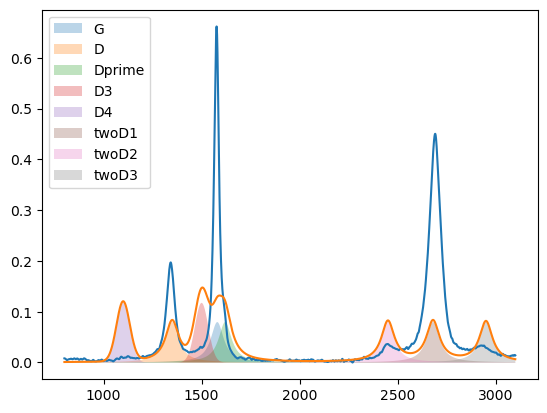

In [ ]:
# I am using pseudoVoigt peaks instead of proper Voigts. This has
# several advantages:
# 1. They are a good approximation to Voigt peaks
# 2. They are much faster to calculate
# 3. I actually understand the mathematics

G = PseudoVoigtModel(prefix='G_')
D = PseudoVoigtModel(prefix='D_')
Dprime = PseudoVoigtModel(prefix='Dprime_')
D3 = PseudoVoigtModel(prefix='D3_')
D4 = PseudoVoigtModel(prefix='D4_')
twoD1 = PseudoVoigtModel(prefix='twoD1_')
twoD2 = PseudoVoigtModel(prefix='twoD2_')
twoD3 = PseudoVoigtModel(prefix='twoD3_')
model = G + D + Dprime + D3 + D4 + twoD1 + twoD2 + twoD3
params = model.make_params()

# Here I set the starting and range parameters for the bands
# based on what has worked for me in the past.
# Importantly, since we normalized the spectra in the first
# part, our starting choice of amplitudes is independent
# on the amount of signal we have. Furthermore, the amplitude
# is the intensity under the peak (not the height) in % of the total
# area, so you don't need to integrate the peaks later.
# Fraction is how close to gaussian or lorentzian the peak is:
# fraction = 0 for gaussian and =1 for lorentzian.

# --- Set G-band parameters ---
params['G_center'].set(1580, min=1550, max=1650)
params['G_sigma'].set(40, min=1)
params['G_fraction'].set(1, vary=False)
params['G_amplitude'].set(10, min=0)

# --- Set D-band parameters ---
params['D_center'].set(1350, min=1300, max=1400)
params['D_sigma'].set(40, min=1)
params['D_fraction'].set(1, vary=False)
params['D_amplitude'].set(10, min=0)

# --- Set Dprime-band parameters ---
params['Dprime_center'].set(1620, min=1580, max=1700)
params['Dprime_sigma'].set(40, min=1)
params['Dprime_fraction'].set(1, min=0, max=1)
params['Dprime_amplitude'].set(10, min=0)

# --- Set D3-band parameters ---
params['D3_center'].set(1500, min=1420, max=1520)
params['D3_sigma'].set(40, min=1)
params['D3_fraction'].set(0, min=0, max=1)
params['D3_amplitude'].set(10, min=0)

# --- Set D4-band parameters ---
params['D4_center'].set(1100, min=1000, max=1250)
params['D4_sigma'].set(40, min=1)
params['D4_fraction'].set(0, min=0, max=1)
params['D4_amplitude'].set(10, min=0)

# --- Set twoD1-band parameters ---
params['twoD1_center'].set(2680, min=2600, max=2700)
params['twoD1_sigma'].set(40, min=1)
params['twoD1_fraction'].set(1, min=0, max=1)
params['twoD1_amplitude'].set(10, min=0)

# --- Set twoD2-band parameters ---
params['twoD2_center'].set(2450, min=2400, max=2500)
params['twoD2_sigma'].set(40, min=1)
params['twoD2_fraction'].set(1, min=0, max=1)
params['twoD2_amplitude'].set(10, min=0)

# --- Set twoD3-band parameters ---
params['twoD3_center'].set(2950, min=2900, max=3000)
params['twoD3_sigma'].set(40, min=1)
params['twoD3_fraction'].set(1, min=0, max=1)
params['twoD3_amplitude'].set(10, min=0)

In [39]:
# We do the actual fitting here:
result = model.fit(y, params, x=x)
# print(result.fit_report())

/home/jrr/miniconda3/envs/general/lib/python3.14/site-packages/uncertainties/core.py:526: FutureWarning: AffineScalarFunc.error_components() is currently an instance method. This method is deprecated. In a future release it will be replaced with an instance property by the same name. It will be accessed by AffineScalarFunc.error_components (with no parentheses).
  return float(sqrt(sum(delta**2 for delta in self.error_components().values())))
/home/jrr/miniconda3/envs/general/lib/python3.14/site-packages/uncertainties/core.py:491: FutureWarning: AffineScalarFunc.derivatives() is deprecated. It will be removed in a future release.
  for variable, derivative in self.derivatives.items():
/home/jrr/miniconda3/envs/general/lib/python3.14/site-packages/uncertainties/core.py:526: FutureWarning: AffineScalarFunc.error_components() is currently an instance method. This method is deprecated. In a future release it will be replaced with an instance property by the same name. It will be accessed b

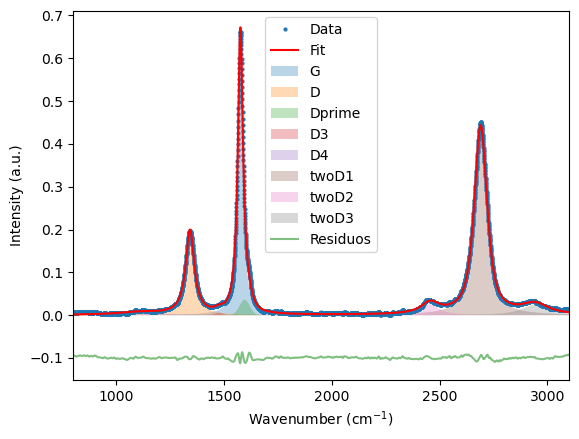

In [40]:
# And the plotting is here:
plt.plot(x, y, 'o', markersize=2, label="Data")
plt.plot(x, result.best_fit, 'r-', label="Fit")
comps = result.eval_components(x=x)
for key in comps:
    # plt.plot(x, comps[key], '--', label=key.replace("_",""))
    plt.fill_between(x, comps[key], baseline, alpha=0.3, label=key.replace("_",""))
plt.plot(x, y - result.best_fit - 0.1, 'g-', alpha=0.5, label="Residuos")
plt.legend()
plt.xlim(xmin, xmax);
plt.xlabel(r"Wavenumber (cm$^{-1}$)")
plt.ylabel("Intensity (a.u.)")
plt.show()

In [52]:
# Finally a few lines to export the fitted data
# to excel. It uses Pandas, a data frame library.
# you don't need to worry about it now.
# Split keys at '_' (first occurrence) and '-'
# Split keys at '_' (first occurrence) and '-'

result_dict = {}
for key in result.params:
  result_dict[key + '-value'] = result.params[key].value
  result_dict[key + '-stderr'] = result.params[key].stderr

result_dict['G/D_ratio-value'] = (result.params['G_amplitude'].value) / (
                                  result.params['D_amplitude'].value)
result_dict['G/D_ratio-stderr'] = result_dict['G/D_ratio-value'] * (
    result.params['G_amplitude'].stderr / result.params['G_amplitude'].value +
    result.params['D_amplitude'].stderr / result.params['D_amplitude'].value)

tuples = []
for key in result_dict:
    first, rest = key.split('_', 1)
    param, stat = rest.split('-', 1)
    tuples.append((first, param, stat))

index = pd.MultiIndex.from_tuples(tuples)
sr = pd.Series(result_dict.values(), index=index)

# Unstack to get a DataFrame
df = sr.unstack(level=-1).sort_index(axis=1, ascending=False)
df.to_excel(r"result_table.xlsx")

In [51]:
plot_df = pd.DataFrame()
plot_df['x'] = x
plot_df['yobs'] = y
plot_df['yfit'] = result.best_fit
plot_df['diff'] = y - result.best_fit

for comp in comps:
    plot_df[comp.replace('_','')] = comps[comp]

plot_df
plot_df.to_excel("result_plot.xlsx")